## EPLORE DATA

**understand structure**

In [2]:
import pandas as pd

data = pd.read_csv('../data/student_mental_health.csv')

print(data.shape)

num_cols = data.select_dtypes(include="number").columns.tolist()
text_cols = data.select_dtypes(include=["object","string"]).columns.tolist()

print("------------------------------------------")
print("numeric columns:", num_cols)
print("string columns:", text_cols)
print("------------------------------------------")
display(data.head(5))

(2000, 17)
------------------------------------------
numeric columns: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
string columns: ['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']
------------------------------------------


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


**check data quality and health**

In [ ]:
print(data.isna().sum())
print("---------------------------")
print(data.duplicated().sum())
print("---------------------------")
print((data[num_cols] < 0).sum())

**outliers**

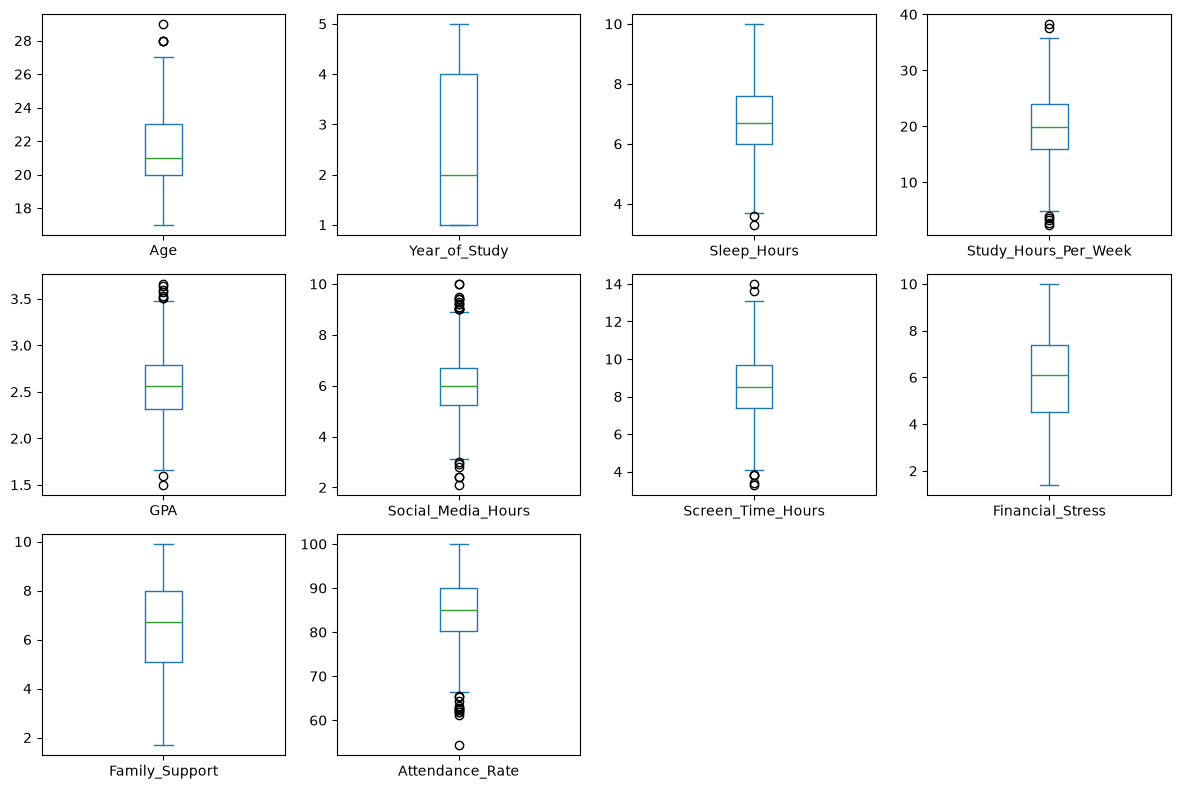

In [4]:
import matplotlib.pyplot as plt


data[num_cols].plot(kind='box', subplots=True, layout=(3, 4), figsize=(12, 8))
plt.tight_layout()
plt.show()

# statistics

In [ ]:
num_cols = data.select_dtypes(include="number")
text_cols = data.select_dtypes(include=["object","string"])

print(num_cols.mean())
print("------------------")
print(num_cols.median())

# analyze target variable

In [ ]:
# unique classes
print(data['Mental_Health_Risk'].unique())
print('---------------------------')
# count per class
print(data['Mental_Health_Risk'].value_counts())
print('---------------------------')
# percentage per class (check imbalance)
print(data['Mental_Health_Risk'].value_counts(normalize=True) * 100)
print('---------------------------')
# check for missing values in the target
print(data['Mental_Health_Risk'].isnull().sum())

# relation between target and other features

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = data.select_dtypes(include="number").columns.tolist()
text_cols = data.select_dtypes(include=["object","string"]).columns.tolist()


num_features = data.groupby('Mental_Health_Risk')[num_cols].mean()
display(num_features)


cat_cols = ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']

for col in cat_cols:
    print(f"--- {col} vs Mental_Health_Risk (%) ---")
    display(pd.crosstab(data[col], data['Mental_Health_Risk'], normalize='index') * 100)
    print("\n")



# Example: Sleep Hours across Risk levels
sns.barplot(data=data, x='Mental_Health_Risk', y='Sleep_Hours')
plt.title('Average Sleep Hours by Mental Health Risk')
plt.show()

# For Categorical Features (Diet Quality vs Risk)
sns.countplot(data=data, x='Diet_Quality', hue='Mental_Health_Risk')
plt.title('Diet Quality by Mental Health Risk')
plt.show()

# correlation between numerical features

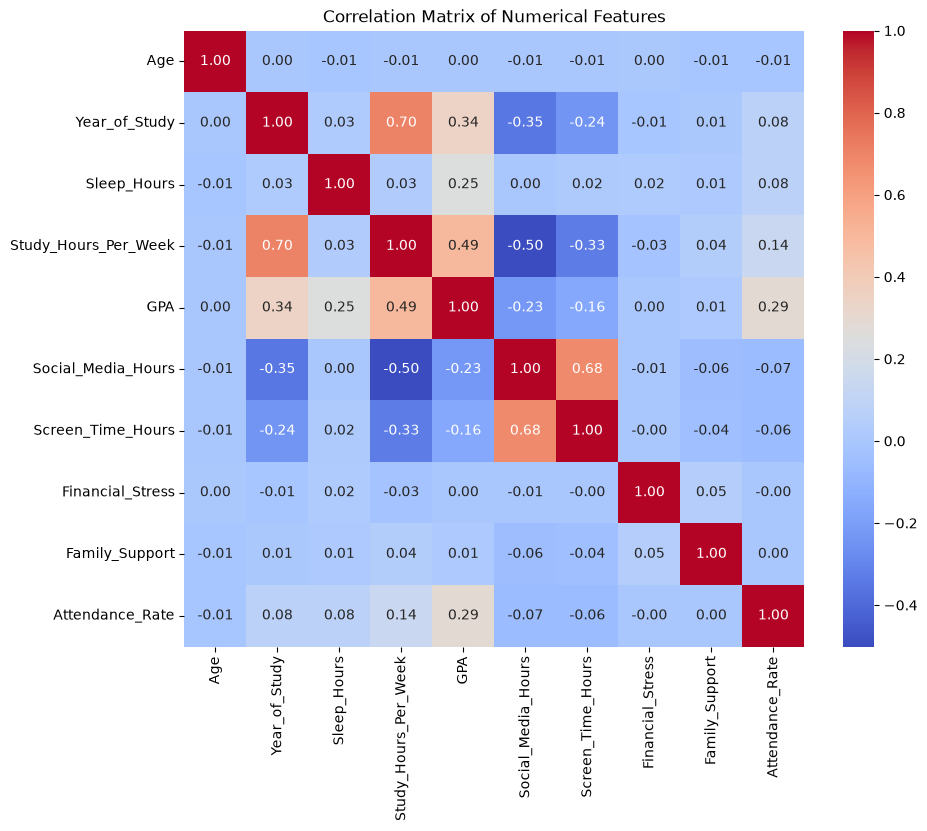

In [44]:
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Numerical Features")
plt.show()

# summarize

### Key Insights & Strongest Risk Factors

1. **Target Variable Balance**:
   - The target `Mental_Health_Risk` is perfectly balanced (~34% High, 33% Medium, 33% Low). No sampling techniques (like SMOTE) are needed for class imbalance.

2. **Top Numerical Factors Linked to High Risk**:
   - **Sleep Hours**: Strong negative link. High-risk students sleep noticeably less (~6.0h vs 7.5h for low-risk).
   - **Financial Stress**: Strong positive link. High-risk students report higher financial stress (~6.7 vs 5.2).
   - **Family Support**: Strong protective factor. Lower support correlates with higher risk (~5.9 vs 7.1).
   - **GPA & Study Hours**: High-risk students have lower GPA (~2.42 vs 2.72) and study fewer hours.
   - **Age**: Average is ~21 across all groups (weak predictor).

3. **Top Categorical Factors Linked to High Risk**:
   - **Previous Mental Health History**: Strongest categorical predictor (~50% of students with past history are in the High-Risk group).
   - **Physical Activity**: Students with low activity are more than twice as likely to be high-risk compared to those with high activity (46% vs 20%).
   - **Diet Quality**: Poor diet is strongly associated with high risk (42% vs 27% for good diet).
   - **Part-Time Job**: Students working a part-time job show higher risk (41% vs 30%).
   - **Gender**: Little to no difference across genders.

4. **Preparation for Step 2 (Cleaning & Preprocessing)**:
   - Missing values need imputation (found in `Sleep_Hours`, `GPA`, `Social_Media_Hours`, `Financial_Stress`, `Family_Support`, `Attendance_Rate`, and `Diet_Quality`).
   - Need to check and treat outliers before scaling.
   - Encode categorical features (`Diet_Quality`, `Physical_Activity`, etc.).
   - Drop `Student_ID` (irrelevant identifier).